 nettoyage, classifieur, Grad-CAM, généralisation
Projet : détection des maladies des plantes + assistant textuel (RAG)

Plan : 1) préparation, 2) nettoyage, 3) découpage sans fuite, 4) chargement des images, 5) modèles, 6) entraînement, 7) évaluation et test de généralisation (PlantVillage vers PlantDoc), 8) confiance, 9) Grad-CAM, 10) fonction `predict`.



## 1. Préparation

In [1]:
import os, json, hashlib, random, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Appareil utilisé :", device)   # doit afficher cuda

Appareil utilisé : cuda



- "cuda" veut dire que le notebook utilise un GPU. L'entraînement des modèles est donc beaucoup plus rapide qu'avec un CPU.

In [2]:
# Télécharger les données (si elles ne sont pas déjà là)
if not os.path.exists("PlantVillage-Dataset"):
    !git clone --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git
if not os.path.exists("PlantDoc-Dataset"):
    !git clone --depth 1 https://github.com/pratikkayal/PlantDoc-Dataset.git

PV_DIR = Path("PlantVillage-Dataset/raw/color")
PD_TRAIN = Path("PlantDoc-Dataset/train")
PD_TEST = Path("PlantDoc-Dataset/test")
EXTS = {".jpg", ".jpeg", ".png"}

Cloning into 'PlantVillage-Dataset'...
remote: Enumerating objects: 163219, done.
remote: Counting objects: 100% (163219/163219), done.
remote: Compressing objects: 100% (163125/163125), done.
remote: Total 163219 (delta 93), reused 163215 (delta 93), pack-reused 0 (from 0)
Receiving objects: 100% (163219/163219), 2.00 GiB | 23.47 MiB/s, done.
Resolving deltas: 100% (93/93), done.
Updating files: 100% (182404/182404), done.
Cloning into 'PlantDoc-Dataset'...
remote: Enumerating objects: 2628, done.
remote: Counting objects: 100% (2628/2628), done.
remote: Compressing objects: 100% (2627/2627), done.
remote: Total 2628 (delta 1), reused 2616 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (2628/2628), 932.91 MiB | 26.82 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Updating files: 100% (2581/2581), done.


## 2. Nettoyage des données
On ne supprime aucun fichier. On crée une **liste propre** :
- on enlève les doublons exacts (on garde une copie) ;
- on enlève du test PlantDoc les images qui sont aussi dans l'entraînement ;
- on enlève la classe PlantDoc qui n'a que 2 images.

In [3]:
def index_dataset(root, name):
    rows = []
    for cls_dir in sorted(p for p in Path(root).iterdir() if p.is_dir()):
        for f in cls_dir.iterdir():
            if f.suffix.lower() in EXTS:
                rows.append({"dataset": name, "classe": cls_dir.name, "chemin": str(f)})
    return pd.DataFrame(rows)

def md5(p):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""): h.update(chunk)
    return h.hexdigest()

df = pd.concat([index_dataset(PV_DIR, "PlantVillage"),
                index_dataset(PD_TRAIN, "PlantDoc-train"),
                index_dataset(PD_TEST, "PlantDoc-test")], ignore_index=True)
df["md5"] = [md5(p) for p in tqdm(df["chemin"])]

train_md5 = set(df[df.dataset == "PlantDoc-train"].md5)
df_clean = df[~((df.dataset == "PlantDoc-test") & df.md5.isin(train_md5))]
df_clean = df_clean.drop_duplicates(subset=["dataset", "md5"])
df_clean = df_clean[df_clean.classe != "Tomato two spotted spider mites leaf"]

avant = df.groupby("dataset").size(); apres = df_clean.groupby("dataset").size()
print(pd.DataFrame({"avant": avant, "après": apres, "enlevées": avant - apres}))

100%|██████████| 56883/56883 [00:22<00:00, 2534.19it/s]

                avant  après  enlevées
dataset                               
PlantDoc-test     236    225        11
PlantDoc-train   2342   2339         3
PlantVillage    54305  54284        21


**Nettoyage des données :** Nous avons utilisé l’empreinte **MD5** sur 56 883 images pour détecter les doublons. Nous avons retiré les images dupliquées et les images communes entre l’entraînement et le test afin d’éviter la **fuite de données**. Aucun fichier original n’a été supprimé : nous avons simplement créé une liste propre des images.

## 3. Classes communes et découpage sans fuite

In [4]:
mapping_final = {
    "Apple Scab Leaf": "Apple___Apple_scab", "Apple leaf": "Apple___healthy",
    "Apple rust leaf": "Apple___Cedar_apple_rust", "Bell_pepper leaf": "Pepper,_bell___healthy",
    "Bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot", "Blueberry leaf": "Blueberry___healthy",
    "Cherry leaf": "Cherry_(including_sour)___healthy",
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn leaf blight": "Corn_(maize)___Northern_Leaf_Blight", "Corn rust leaf": "Corn_(maize)___Common_rust_",
    "Peach leaf": "Peach___healthy", "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight", "Raspberry leaf": "Raspberry___healthy",
    "Soyabean leaf": "Soybean___healthy", "Squash Powdery mildew leaf": "Squash___Powdery_mildew",
    "Strawberry leaf": "Strawberry___healthy", "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot", "Tomato leaf": "Tomato___healthy",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot", "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold", "grape leaf": "Grape___healthy",
    "grape leaf black rot": "Grape___Black_rot",
}
pv = df_clean[df_clean.dataset == "PlantVillage"].copy()
pdoc = df_clean[df_clean.dataset.str.startswith("PlantDoc")].copy()
pdoc["classe_pv"] = pdoc.classe.map(mapping_final)
pdoc = pdoc.dropna(subset=["classe_pv"])

CLASSES = sorted(set(pdoc.classe_pv))
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
pv = pv[pv.classe.isin(CLASSES)].copy()
print(len(CLASSES), "classes communes |", len(pv), "images PlantVillage |", len(pdoc), "images PlantDoc")

27 classes communes | 36845 images PlantVillage | 2564 images PlantDoc


Nous avons gardé les 27 classes communes entre PlantVillage et PlantDoc. Nous utilisons PlantVillage pour entraîner le modèle et PlantDoc pour le tester sur des images différentes, prises dans des conditions réelles.

In [5]:
# Groupe = identifiant de la feuille d'origine (partie du nom avant '___').
# Toutes les photos de la même feuille restent du même côté (pas de fuite).
def groupe(p):
    n = Path(p).name
    return n.split("___")[0] if "___" in n else n
pv["groupe"] = pv.chemin.apply(groupe)

def split_groups(d, test_size):
    a, b = next(GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=SEED).split(d, groups=d.groupe))
    return d.iloc[a], d.iloc[b]

pv_trval, pv_test = split_groups(pv, 0.15)
pv_train, pv_val = split_groups(pv_trval, 0.15)

def cap(d, n):   # au plus n images par classe (pour aller vite)
    return d.groupby("classe", group_keys=False).apply(lambda g: g.sample(min(len(g), n), random_state=SEED))

N_TRAIN = 250     # images par classe pour l'entraînement (augmente si tu as du temps)
pv_train, pv_val, pv_test = cap(pv_train, N_TRAIN), cap(pv_val, 60), cap(pv_test, 100)
pd_test = pdoc[pdoc.dataset == "PlantDoc-test"]
pd_all = pdoc
print("train", len(pv_train), "| val", len(pv_val), "| test PlantVillage", len(pv_test),
      "| test PlantDoc", len(pd_test), "| PlantDoc toutes", len(pd_all))

train 6708 | val 1560 | test PlantVillage 2448 | test PlantDoc 225 | PlantDoc toutes 2564


/tmp/ipykernel_1252/4053541234.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby("classe", group_keys=False).apply(lambda g: g.sample(min(len(g), n), random_state=SEED))
/tmp/ipykernel_1252/4053541234.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby("classe", group_keys=False).apply(lambda g: g.sample(min(len(g), n), random_state=SEED))
/tmp/ipykernel_1252/4053541234

Nous avons divisé PlantVillage en trois parties : entraînement, validation et test. Nous avons limité le nombre d'images par classe pour accélérer le traitement. Les images d'une même feuille restent dans la même partie pour éviter la fuite de données. Enfin, PlantDoc est réservé au test sur des images réelles et différentes. Le modèle ne voit jamais PlantDoc pendant l'entraînement.

## 4. Chargement des images (prétraitement)
Conversion en RGB, redimensionnement 224 x 224, normalisation.

In [7]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf_train = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)), transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20), transforms.ColorJitter(0.3, 0.3, 0.3),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
tf_eval = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

def open_rgb(path):
    im = Image.open(path)
    try: im.draft("RGB", (512, 512))   # lecture rapide des très grandes images JPEG
    except Exception: pass
    return im.convert("RGB")           # règle aussi CMYK, RGBA, niveaux de gris

class LeafDS(Dataset):
    def __init__(self, d, label_col, tf):
        self.paths = d.chemin.tolist(); self.y = [class_to_idx[c] for c in d[label_col]]; self.tf = tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i): return self.tf(open_rgb(self.paths[i])), self.y[i]

def loader(d, label_col, tf, shuffle=False, bs=32):
    return DataLoader(LeafDS(d, label_col, tf), batch_size=bs, shuffle=shuffle, num_workers=2, pin_memory=True)

dl_train = loader(pv_train, "classe", tf_train, shuffle=True)
dl_val = loader(pv_val, "classe", tf_eval)
dl_pv_test = loader(pv_test, "classe", tf_eval)
dl_pd_test = loader(pd_test, "classe_pv", tf_eval)
dl_pd_all = loader(pd_all, "classe_pv", tf_eval)

Nous avons converti toutes les images en RGB et les avons redimensionnées à 224 × 224 pixels, puis normalisées. Pendant l'entraînement, nous ajoutons des transformations aléatoires comme la rotation et le retournement pour améliorer la généralisation. Pour la validation et le test, nous gardons les images sans modification aléatoire.

## 5. Les modèles
On compare un CNN (**ResNet50**) et un Transformer (**ViT-B/16**), tous deux pré-entraînés sur ImageNet (transfer learning).

In [9]:
def build_model(name):
    n = len(CLASSES)
    if name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2); m.fc = nn.Linear(m.fc.in_features, n)
    elif name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n)
    elif name == "vit_b_16":
        m = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1); m.heads.head = nn.Linear(m.heads.head.in_features, n)
    return m.to(device)

@torch.no_grad()
def predict_loader(model, dl):
    model.eval(); P, Y = [], []
    for x, y in dl:
        with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
            p = F.softmax(model(x.to(device)).float(), dim=1)
        P.append(p.cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def train_model(name, epochs=3, lr=1e-4):
    model = build_model(name)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
    for ep in range(epochs):
        model.train(); tot = 0
        for x, y in tqdm(dl_train, desc=f"{name} epoch {ep+1}/{epochs}"):
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
                loss = F.cross_entropy(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tot += loss.item()
        P, Y = predict_loader(model, dl_val)
        print(f"  perte {tot/len(dl_train):.3f} | précision validation {accuracy_score(Y, P.argmax(1)):.3f}")
    return model

## 6. Entraînement (quelques minutes par modèle)

In [10]:
models_trained = {}
models_trained["resnet50"] = train_model("resnet50", epochs=3)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 127MB/s]
/tmp/ipykernel_1252/916595769.py:24: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
resnet50 epoch 1/3: 100%|██████████| 210/210 [00:44<00:00,  4.69it/s]


  perte 1.087 | précision validation 0.946


resnet50 epoch 2/3: 100%|██████████| 210/210 [00:44<00:00,  4.74it/s]


  perte 0.144 | précision validation 0.976


resnet50 epoch 3/3: 100%|██████████| 210/210 [00:43<00:00,  4.88it/s]


  perte 0.101 | précision validation 0.983


In [11]:
models_trained["vit_b_16"] = train_model("vit_b_16", epochs=3, lr=5e-5)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:07<00:00, 46.3MB/s]
/tmp/ipykernel_1252/916595769.py:24: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
vit_b_16 epoch 1/3: 100%|██████████| 210/210 [01:12<00:00,  2.88it/s]


  perte 0.527 | précision validation 0.967


vit_b_16 epoch 2/3: 100%|██████████| 210/210 [01:11<00:00,  2.93it/s]


  perte 0.072 | précision validation 0.979


vit_b_16 epoch 3/3: 100%|██████████| 210/210 [01:12<00:00,  2.91it/s]


  perte 0.065 | précision validation 0.974


Nous avons entraîné deux modèles pré-entraînés : ResNet50 et ViT-B/16 pendant 3 epochs. La loss diminue, ce qui montre que les modèles apprennent. La précision sur la validation atteint 98,3 % pour ResNet50 et 97,4 % pour ViT. Cependant, ces résultats sont obtenus sur PlantVillage et doivent être confirmés sur PlantDoc. ResNet50 est également plus rapide que ViT.

## 7. Évaluation et test de généralisation
On entraîne sur PlantVillage (laboratoire) et on teste sur :
- le test PlantVillage (même type d'images) ;
- PlantDoc (photos de terrain, jamais vues).

  modèle       jeu de test  précision  F1 macro
resnet50 PlantVillage test      0.979     0.980
resnet50     PlantDoc test      0.311     0.260
resnet50   PlantDoc toutes      0.228     0.192
vit_b_16 PlantVillage test      0.973     0.975
vit_b_16     PlantDoc test      0.298     0.222
vit_b_16   PlantDoc toutes      0.222     0.175


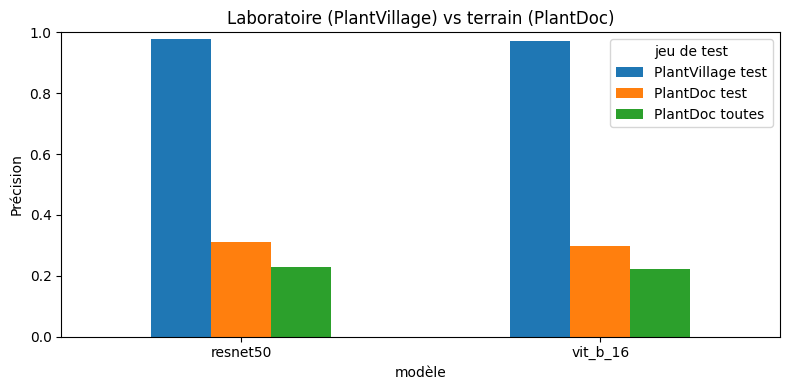

In [12]:
rows, store = [], {}
for name, m in models_trained.items():
    for dname, dl in [("PlantVillage test", dl_pv_test), ("PlantDoc test", dl_pd_test), ("PlantDoc toutes", dl_pd_all)]:
        P, Y = predict_loader(m, dl); pred = P.argmax(1); store[(name, dname)] = (P, Y)
        rows.append({"modèle": name, "jeu de test": dname, "précision": accuracy_score(Y, pred),
                     "F1 macro": f1_score(Y, pred, average="macro")})
res = pd.DataFrame(rows); res["précision"] = res["précision"].round(3); res["F1 macro"] = res["F1 macro"].round(3)
print(res.to_string(index=False)); res.to_csv("resultats_generalisation.csv", index=False)

piv = res.pivot(index="modèle", columns="jeu de test", values="précision")[["PlantVillage test", "PlantDoc test", "PlantDoc toutes"]]
piv.plot.bar(figsize=(8, 4)); plt.ylabel("Précision"); plt.title("Laboratoire (PlantVillage) vs terrain (PlantDoc)")
plt.xticks(rotation=0); plt.ylim(0, 1); plt.tight_layout(); plt.show()

Les résultats montrent une bonne précision sur PlantVillage, mais une forte diminution sur PlantDoc. Les deux modèles font mieux que le hasard, mais leur capacité de généralisation reste faible. Cela montre que les bonnes performances en laboratoire ne garantissent pas de bons résultats sur des photos réelles. Les principales limites sont le faible nombre d'epochs, le nombre limité d'images et les erreurs possibles d'étiquetage.

In [13]:
# Classes les plus difficiles sur PlantDoc (meilleur modèle)
best = res[res["jeu de test"] == "PlantDoc toutes"].sort_values("précision", ascending=False).iloc[0]["modèle"]
P, Y = store[(best, "PlantDoc toutes")]
acc_cls = pd.Series({CLASSES[c]: (P.argmax(1)[Y == c] == c).mean() for c in np.unique(Y)}).sort_values()
print("Meilleur modèle :", best); print(acc_cls.head(8).round(2))

Meilleur modèle : resnet50
Cherry_(including_sour)___healthy    0.00
Tomato___healthy                     0.00
Soybean___healthy                    0.02
Tomato___Tomato_mosaic_virus         0.02
Tomato___Leaf_Mold                   0.02
Tomato___Bacterial_spot              0.03
Strawberry___healthy                 0.04
Apple___healthy                      0.08
dtype: float64


L'analyse montre que les classes les plus difficiles sont principalement les feuilles saines (Healthy) et certaines maladies de la tomate. Le modèle reconnaît difficilement les feuilles saines sur les images de PlantDoc. Cela peut être dû aux différences entre les images de laboratoire de PlantVillage et les photos réelles de PlantDoc. Par conséquent, le système peut faire des erreurs même sur une feuille saine.

## 8. Confiance du modèle
Utile pour la Personne 3 : choisir le seuil en dessous duquel le système demande une meilleure photo.

Confiance moyenne quand le modèle a raison : 0.64
Confiance moyenne quand le modèle se trompe : 0.52


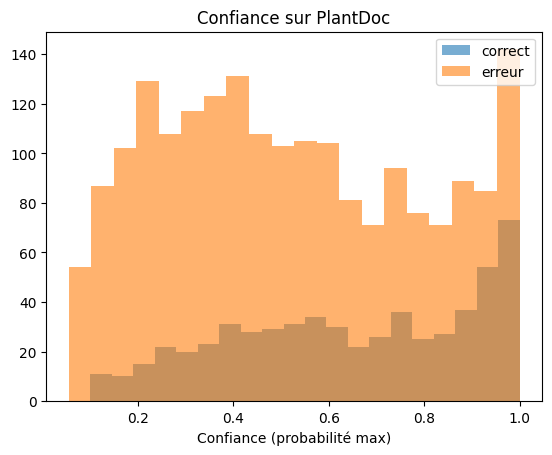

seuil 0.5: 54% des images gardées, précision sur celles-ci = 0.29
seuil 0.7: 33% des images gardées, précision sur celles-ci = 0.32
seuil 0.9: 15% des images gardées, précision sur celles-ci = 0.36


In [14]:
P, Y = store[(best, "PlantDoc toutes")]
conf = P.max(1); ok = P.argmax(1) == Y
print(f"Confiance moyenne quand le modèle a raison : {conf[ok].mean():.2f}")
print(f"Confiance moyenne quand le modèle se trompe : {conf[~ok].mean():.2f}")
plt.hist(conf[ok], bins=20, alpha=.6, label="correct"); plt.hist(conf[~ok], bins=20, alpha=.6, label="erreur")
plt.xlabel("Confiance (probabilité max)"); plt.legend(); plt.title("Confiance sur PlantDoc"); plt.show()
for seuil in [0.5, 0.7, 0.9]:
    garde = conf >= seuil
    print(f"seuil {seuil}: {garde.mean()*100:.0f}% des images gardées, précision sur celles-ci = {ok[garde].mean():.2f}")

Le modèle ResNet50 peut être très confiant même lorsqu'il donne une prédiction incorrecte. Avec un seuil de confiance de 0,9, seulement 15 % des images sont conservées et la précision atteint 36 %. Cela montre que la confiance seule ne suffit pas pour éviter les erreurs. Ce problème est important pour notre système RAG, car un mauvais diagnostic peut entraîner des conseils incorrects. C'est ce qu'on appelle la propagation des erreurs.

## 9. Grad-CAM (zones regardées par le modèle, ResNet50)

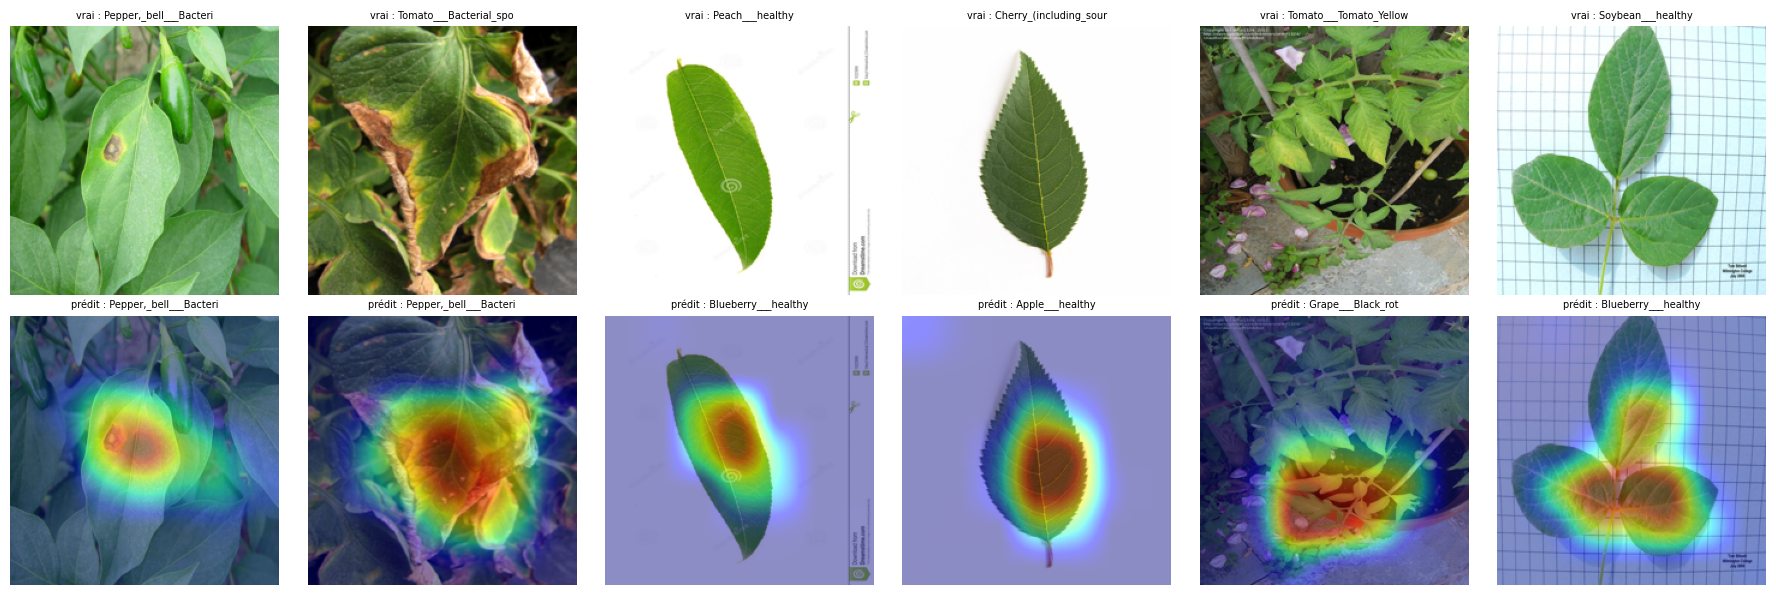

In [15]:
def gradcam(model, x):
    feats = []
    def hook(m, i, o): o.retain_grad(); feats.append(o)
    h = model.layer4.register_forward_hook(hook)
    model.eval(); out = model(x.unsqueeze(0).to(device)); c = out.argmax(1).item()
    model.zero_grad(); out[0, c].backward(); h.remove()
    w = feats[0].grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * feats[0]).sum(1)).squeeze().detach().cpu().numpy()
    return (cam - cam.min()) / (cam.max() + 1e-8), c

m = models_trained["resnet50"]
sample = pd_test.sample(6, random_state=1)
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for k, (_, r) in enumerate(sample.iterrows()):
    img = open_rgb(r.chemin).resize((224, 224))
    cam, c = gradcam(m, tf_eval(img))
    axes[0, k].imshow(img); axes[0, k].axis("off"); axes[0, k].set_title("vrai : " + r.classe_pv[:22], fontsize=7)
    axes[1, k].imshow(img); axes[1, k].imshow(np.array(Image.fromarray((cam*255).astype("uint8")).resize((224, 224))), cmap="jet", alpha=.45)
    axes[1, k].axis("off"); axes[1, k].set_title("prédit : " + CLASSES[c][:22], fontsize=7)
plt.tight_layout(); plt.show()

Grad-CAM permet de visualiser les zones de l'image utilisées par le modèle pour prendre sa décision. Sur les 6 images analysées, une seule prédiction est correcte. Nous avons remarqué que les fonds complexes peuvent perturber le modèle. Cependant, ces résultats restent indicatifs, car l'analyse porte seulement sur 6 images.

## 10. Fonction `predict(image)` (contrat avec le reste du projet) et sauvegarde

In [16]:
def predict(image, model=None):
    """image : chemin (str) ou image PIL. Retourne {"top3": [(maladie, proba), ...]}"""
    model = model or models_trained[best]
    img = open_rgb(image) if isinstance(image, (str, Path)) else image.convert("RGB")
    model.eval()
    with torch.no_grad():
        p = F.softmax(model(tf_eval(img).unsqueeze(0).to(device)).float(), dim=1)[0].cpu().numpy()
    top = p.argsort()[::-1][:3]
    return {"top3": [(CLASSES[i], float(p[i])) for i in top]}

print(predict(pd_test.chemin.iloc[0]))

torch.save(models_trained[best].state_dict(), f"modele_{best}.pt")
json.dump(CLASSES, open("classes.json", "w"), ensure_ascii=False, indent=1)
print("Fichiers sauvegardés : modele_%s.pt, classes.json, resultats_generalisation.csv" % best)

{'top3': [('Pepper,_bell___Bacterial_spot', 0.35721540451049805), ('Tomato___Late_blight', 0.14305685460567474), ('Tomato___Early_blight', 0.12426304817199707)]}
Fichiers sauvegardés : modele_resnet50.pt, classes.json, resultats_generalisation.csv


La fonction predict prend une image en entrée et retourne les trois maladies les plus probables avec leurs probabilités. Par exemple, pour une image de PlantDoc, ResNet50 prédit Pepper bell Bacterial spot avec une probabilité de 36 %. Cette confiance est faible, donc le système peut demander une image plus claire. Les noms des classes seront reliés à ceux de la base de connaissances pour permettre l'utilisation du RAG.